<!--
Copyright 2026 EUMETSAT

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
You may obtain a copy of the License at

    http://www.apache.org/licenses/LICENSE-2.0

Unless required by applicable law or agreed to in writing, software
distributed under the License is distributed on an "AS IS" BASIS,
WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
See the License for the specific language governing permissions and
limitations under the License.
-->

# Unit Write Buffer: Sharded MTG FCI L1C To S3

Turn **two hours of FCI observations into one Zarr cube** on S3, with 12 processes.
Run it once with the unit write buffer off and once with it on.
The recorded runs took about 364 seconds without the buffer and about 91 seconds with it.
Then measure the difference on your own bucket.

## How The Buffer Works

A stored unit is the piece of an array that Firecube writes as one object: a shard, or a chunk without shards.
The default layout of the plugin uses shards, and the plugin writes the data in pieces that are smaller than a shard.
Without the buffer, each piece makes Firecube read the whole shard back from S3 and merge the piece.
Firecube then uploads the shard again, so each shard goes to S3 many times.
With `zarr_unit_write_buffer=true`, Firecube collects the pieces of each stored unit in memory and writes each complete unit once.
The price is more memory in each process.
The store is the same with the buffer on or off.



*The same three pieces reach the same stored unit. The buffer changes how many times the unit travels.*
[How The Unit Write Buffer Works](https://eumetsat.github.io/firecube/latest/concepts/output-formats/zarr/unit-write-buffer/) explains the mechanism, the supported codecs and when the buffer helps.

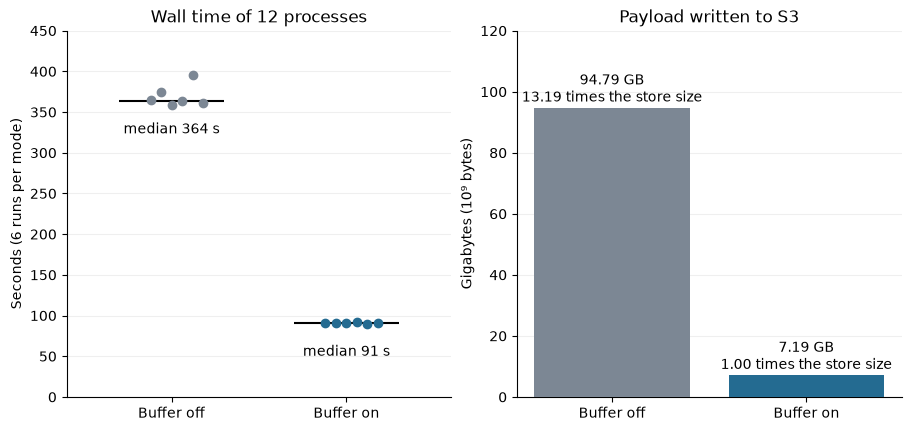

*Recorded wall time of 12 processes and payload written to S3, 6 runs per mode.*
[Benchmarks](https://eumetsat.github.io/firecube/latest/concepts/benchmarks/#unit-write-buffer-sharded-s3) lists the conditions of those runs.

| Recorded result | Buffer off | Buffer on |
| --- | --- | --- |
| Wall time, median | 364 s | 91 s |
| Payload written to S3 | 94.79 GB | 7.19 GB |
| Payload read back from S3 | 87.6 GB | about 0 |
| Most times one stored unit was written | 40 | 1 |
| Peak memory of the largest of the 11 other processes | 1.1 GiB | 2.55 GiB |
| Peak memory of the process that also writes the static grids | 2.5 GiB | 3.6 GiB |

## When To Use This

Use this notebook when you write sharded Zarr arrays to S3 from several processes.
It measures the unit write buffer on your own bucket and compares your result with the recorded runs.

## Prerequisites

- A Python 3.12 or newer kernel on Linux.
- An S3-compatible bucket with write access and 15 GB free. Step 1 lists the `FIRECUBE_` credential variables.
- EUMDAC credentials to download the data. Step 2 links the setup guide.
- 15 GB free on the local disk. The input files take 6 GB, the grids 1 GB and each process about 0.6 GB of scratch space.
- About 2.6 GiB of RAM for each process with the buffer, and 3.6 GiB for the process that also writes the static grids. Step 3 shows how to choose the process count.

## 1. Set Up Your JupyterHub Kernel

<div class="alert alert-block alert-warning">
<p>Install below, then restart the kernel. Run the cells again from the top.</p>
</div>

In [ ]:
%pip install -r https://eumetsat.github.io/firecube/latest/showcase/unit-write-buffer-requirements.txt

Import the modules that the notebook uses. The cell prints nothing.
The install step puts `firecube` and `eumdac` in the folder of the kernel's Python.
The last line adds that folder to the `PATH`, so that the cells find both commands.

In [ ]:
import hashlib
import json
import os
import re
import shutil
import signal
import subprocess
import sys
import tempfile
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import obstore
import pandas as pd
from obstore.store import S3Store

os.environ["PATH"] = str(Path(sys.executable).parent) + os.pathsep + os.environ["PATH"]

Set these environment variables in the shell that starts the notebook server. Do not write credentials into a cell.

| Variable | Value |
| --- | --- |
| `FIRECUBE_ENDPOINT_URL` | The URL of your S3 endpoint. |
| `FIRECUBE_ACCESS_KEY` | Your access key. |
| `FIRECUBE_SECRET_KEY` | Your secret key. |
| `FIRECUBE_REGION` | Your region. Set it only if your provider needs it. |
| `FIRECUBE_PATH_STYLE` | Set `false` for virtual-hosted addressing. The default is `true`. |

[Configure S3 Access](https://eumetsat.github.io/firecube/latest/operations/s3-access/) explains these variables.
Then set the parameters below. Replace the placeholder in `s3_prefix` with your bucket and a prefix. The notebook writes `off.zarr` and `on.zarr` below it.
Keep `processes = None` to let step 3 choose the number of processes from your RAM. To choose it yourself, set a number that divides 12.

In [ ]:
# Replace the placeholder. The notebook creates off.zarr and on.zarr below this prefix.
s3_prefix = "s3://<your-bucket>/<your-prefix>"

# None lets step 3 choose from your RAM. Otherwise set 12, 6, 4, 3, 2 or 1.
processes = None

source = Path("inputs/fci").resolve()  # step 2 downloads the input files here
grids = Path("fci_grids.npz").resolve()  # step 4 generates this file
output = Path("outputs/fci-s3-buffer").resolve()  # logs and measurement files
output.mkdir(parents=True, exist_ok=True)

Verify the environment. The cell stops with a message if a variable, the placeholder or a tool is missing.
Otherwise it prints `Environment ready` and your region.

In [ ]:
required_variables = ["FIRECUBE_ENDPOINT_URL", "FIRECUBE_ACCESS_KEY", "FIRECUBE_SECRET_KEY"]
problems = [
    f"Set the environment variable {name} before you start the kernel."
    for name in required_variables
    if not os.environ.get(name)
]
if "<" in s3_prefix or not s3_prefix.startswith("s3://"):
    problems.append("Replace the placeholder in s3_prefix with s3://your-bucket/your-prefix.")
if not Path("/usr/bin/time").exists():
    problems.append("Install GNU time (/usr/bin/time). The notebook reads peak memory from it.")
problems += [
    f"The command {tool} is not on the PATH. Install the requirements first."
    for tool in ["firecube", "eumdac"]
    if shutil.which(tool) is None
]
if problems:
    raise RuntimeError("Fix these problems and run the cell again:\n- " + "\n- ".join(problems))
print("Environment ready. Region:", os.environ.get("FIRECUBE_REGION") or "not set")

## 2. Get The Data

With [EUMDAC credentials configured](https://user.eumetsat.int/resources/user-guides/eumetsat-data-access-client-eumdac),
download **12 FDHSI products for 1 July 2025, 00:00–02:00 UTC** (about 6 GB).
Skip the download if the ZIPs are already in `inputs/fci`.

In [ ]:
!eumdac download \
    -c EO:EUM:DAT:0662 \
    -s 2025-07-01T00:00:00 \
    -e 2025-07-01T01:59:59 \
    --limit 12 \
    -o "{source}" \
    --integrity
assert _exit_code == 0, "eumdac download failed - see the output above"

Verify the downloaded files. `inputs/fci` must hold 12 FDHSI products, one every 10 minutes from 00:00 to 01:50 UTC.
The cell prints the number of products.

In [ ]:
zip_files = sorted(source.glob("*.zip"))
start_times = pd.date_range("2025-07-01 00:00", periods=12, freq="10min")
expected_starts = list(start_times.strftime("%Y%m%d%H%M"))
found_starts = []
for zip_file in zip_files:
    assert "FCI-1C-RRAD-FDHSI" in zip_file.name, f"Not an FDHSI product: {zip_file.name}"
    # After "_OPE_" the name holds the start time: 14 digits, YYYYMMDDhhmmss, then "_".
    # (\d{12}) keeps the first 12 digits, the start to the minute. group(1) returns them.
    match = re.search(r"_OPE_(\d{12})\d{2}_", zip_file.name)
    assert match, f"No start time after _OPE_ in {zip_file.name}"
    found_starts.append(match.group(1))
assert sorted(found_starts) == expected_starts, "Expected all 12 products"
print(f"Ready: {len(zip_files)} products")

## 3. Set The Number Of Processes

The buffer raises the memory of each process, so too many processes can exceed your RAM.
With `processes = None` in step 1, this step chooses the largest number that fits and divides 12.
To use another value, set `processes` in step 1. Then run the cells again from the parameters cell.
The cell prints your RAM, the number of processes that fit and the number it uses.

In [ ]:
SLOT0_GIB = 3.6  # peak memory of the process that also writes the static grids
OTHER_GIB = 2.6  # peak memory of each other process

for line in Path("/proc/meminfo").read_text().splitlines():
    if line.startswith("MemTotal"):
        ram_gib = int(line.split()[1]) / 2**20  # /proc/meminfo counts in KiB

fits = min(12, int((ram_gib - SLOT0_GIB) // OTHER_GIB) + 1)  # at most one process per slot
if processes is None:
    processes = 1
    for count in [2, 3, 4, 6, 12]:  # the other numbers that divide 12
        if count <= fits:
            processes = count
assert 12 % processes == 0, "processes must divide the 12 slots"
print(f"{ram_gib:.0f} GiB of RAM: {fits} processes fit, using {processes}.")

## 4. Prepare The Cube

Generate shared latitude and longitude grids once. Each ingest process will reuse them.

In [ ]:
!firecube plugins mtg_fci_l1c geo generate --resolutions 1km,2km --output "{grids}"
assert _exit_code == 0, "firecube plugins mtg_fci_l1c geo generate failed - see the output above"

Both runs use the `processes` value from step 3.
A slot is one 10-minute time step, so the cube has 12 slots.
Each process writes 12 divided by `processes` slots. Its slot range names the first slot and the slot after the last.
Create a run folder for the logs, the GNU time files and the slot plans. The cell prints the slot ranges and the run folder.

In [ ]:
assert grids.is_file(), "Generate the shared grids first"
slot_size = 12 // processes
slot_ranges = [(start, start + slot_size) for start in range(0, 12, slot_size)]
run_dir = Path(tempfile.mkdtemp(prefix="s3-", dir=output))
print(f"Processes: {processes}. Slots per process: {slot_size}. Slot ranges: {slot_ranges}")
print(f"Run folder: {run_dir}")

Keep the settings of the recorded runs: four extraction workers, one concurrent region write, the default sharded layout and no empty-chunk writes.
The dictionary `shared_options` holds the plugin options that both runs share. Each entry becomes one `--option name=value` flag.

In [ ]:
shared_options = {
    "product_type": "FDHSI",
    "time_epoch": "2025-07-01",
    "time_slots": "12",
    "resolutions": "1km,2km",
    "pixel_time_dtype": "float64",
    "include_pixel_time": "true",
    "include_pixel_quality": "true",
    "include_calibration": "true",
    "include_geolocation": "true",
    "pipeline_workers": "1",
    "pipeline_batch_size": "10",
    "extract_workers": "4",
    "zarr_region_write_concurrency": "1",
    "zarr_write_empty_chunks": "false",
}
print(f"{len(shared_options)} shared options")

The runs differ in the target and in the value of `zarr_unit_write_buffer`.
`firecube_flags` returns the flags of one run: the target, the storage settings, the shared options, the buffer value and a scratch folder.
Every firecube command of a run takes these flags.

In [ ]:
def firecube_flags(target_uri, buffer, scratch_dir):
    """Return the flags that every firecube command of one run takes."""
    flags = ["--target", target_uri, "--product-name", "mtg_fci_l1c"]
    flags += ["--storage-type", "s3", "--storage-driver", "obstore", "--write-mode", "direct"]
    options = dict(shared_options)
    options["zarr_unit_write_buffer"] = buffer
    options["fci_grids_file"] = grids
    options["scratch_dir"] = scratch_dir
    for name, value in options.items():
        flags += ["--option", f"{name}={value}"]
    return flags

## 5. Run Without The Buffer

Set `zarr_unit_write_buffer=false`. This is the default value.

In [ ]:
off_uri = f"{s3_prefix}/off.zarr"
off_flags = firecube_flags(off_uri, buffer="false", scratch_dir=run_dir / "off-scratch")
print("Target:", off_uri)

<div class="alert alert-block alert-info">
Create the arrays and time coordinates before you start the clock.
</div>

`preallocate` runs `firecube zarr preallocate` for all 12 slots and writes the output to a log file in the run folder.
The functions of steps 5 and 6 take a mode, `off` or `on`, and use it in the names of their files.

In [ ]:
def preallocate(flags, mode):
    """Create the arrays and time coordinates of all 12 slots."""
    command = ["firecube", "zarr", "preallocate", "mtg_fci_l1c"]
    command += flags
    command += ["--input-data", f"file://{source}", "--slot-start", "0", "--slot-end", "12"]
    log_file = run_dir / f"{mode}-preallocate.log"
    with open(log_file, "w") as log:
        result = subprocess.run(command, stdout=log, stderr=subprocess.STDOUT)
    assert result.returncode == 0, f"firecube zarr preallocate failed - inspect {log_file}"
    print("Store ready: 12 time slots at 1 km and 2 km")


preallocate(off_flags, "off")

Ask Firecube for non-overlapping ranges. Both resolutions must use the same partition.
`read_slot_plan` runs `firecube zarr slots` and returns its JSON output as a dictionary. It also saves the output in the run folder.

In [ ]:
def read_slot_plan(flags, extra_arguments, json_file):
    """Run firecube zarr slots, save its JSON output to json_file and return it as a dictionary."""
    command = ["firecube", "zarr", "slots", "mtg_fci_l1c"]
    command += flags
    command += extra_arguments
    command += ["--format", "json"]
    result = subprocess.run(command, capture_output=True, text=True)
    print(result.stderr, end="")  # the warnings and errors of the command
    assert result.returncode == 0, "firecube zarr slots failed - see the output above"
    json_file.write_text(result.stdout)
    return json.loads(result.stdout)

Verify the plan. Each group must have the slot ranges from step 4, and the slot 0 process must write the static grids.
The cell prints the slot ranges.

In [ ]:
def verify_slot_plan(flags, mode):
    """Stop unless both groups have the slot ranges of step 4 and slot 0 writes the static grids."""
    arguments = ["--slot-size", str(slot_size), "--no-resume"]
    plan = read_slot_plan(flags, arguments, run_dir / f"{mode}-plan.json")
    group_names = {group["name"] for group in plan["groups"]}
    assert group_names == {"data_1km", "data_2km"}, f"Unexpected groups: {group_names}"
    for group in plan["groups"]:
        group_ranges = [
            (slot_range["slot_start"], slot_range["slot_end"])
            for slot_range in plan["ranges"]
            if slot_range["group"] == group["name"]
        ]
        assert sorted(group_ranges) == slot_ranges, f"Other slot ranges in {group['name']}"
        assert group["static_owner"]["slot_start"] == 0, "The slot 0 process must write the grids"
    print("Slot ranges (end excluded):", slot_ranges)


verify_slot_plan(off_flags, "off")

Start the processes. Only the first one writes the static grids.
GNU time records the peak memory of each process.
`ingest_command` returns the command of one process. The cell prints the command of the first process.

In [ ]:
def ingest_command(flags, mode, slot_start, slot_end):
    """Return the command that ingests one slot range under GNU time."""
    time_file = run_dir / f"{mode}-time-{slot_start}.txt"
    command = ["/usr/bin/time", "-v", "-o", str(time_file)]
    command += ["firecube", "ingest", "mtg_fci_l1c"]
    command += flags
    command += ["--input-data", f"file://{source}", "--option", "force_reingest=true"]
    # Only the process that starts at slot 0 writes the static grids.
    command += ["--suppress-static-emission-for-non-owner", "--static-owner-slot-start", "0"]
    command += ["--slot-start", str(slot_start), "--slot-end", str(slot_end)]
    return command


first_start, first_end = slot_ranges[0]
print(" ".join(ingest_command(off_flags, "off", first_start, first_end)))

Run all processes at the same time and measure the wall time. The clock covers only the ingest, because `preallocate` ran before it.
A failed process leaves a `.failed` file beside its log, and the cell stops with the log path.
Each process is `/usr/bin/time`, which starts `firecube` as its child. Both run in a process group of their own.
If an error or the Interrupt button stops the cell, the cell kills each group that still runs.
So no `firecube` process keeps writing to the bucket.

In [ ]:
def ingest_in_parallel(flags, mode):
    """Run one ingest process per slot range at once and return the wall time in seconds."""
    started = time.perf_counter()
    running = []
    try:
        for slot_start, slot_end in slot_ranges:
            command = ingest_command(flags, mode, slot_start, slot_end)
            log_file = run_dir / f"{mode}-slot-{slot_start}-{slot_end}.log"
            with open(log_file, "w") as log:
                # Popen returns at once, so the next process starts before this one ends.
                # A new session gives time and its firecube child a process group of their own.
                process = subprocess.Popen(
                    command, stdout=log, stderr=subprocess.STDOUT, start_new_session=True
                )
            running.append((process, log_file))
        for process, log_file in running:
            if process.wait() != 0:
                log_file.with_suffix(".failed").touch()
        wall_s = time.perf_counter() - started
    finally:
        # After an error or an interrupt, kill each process group that still runs and wait for it.
        for process, _ in running:
            if process.poll() is None:  # still running
                os.killpg(process.pid, signal.SIGKILL)  # SIGKILL cannot be ignored
            process.wait()
    failed = sorted(run_dir.glob(f"{mode}-slot-*.failed"))
    assert not failed, f"Ingest failed: inspect {run_dir}/{mode}-slot-*.log"
    return wall_s


off_wall_s = ingest_in_parallel(off_flags, "off")
print(f"Ingestion without the buffer: {off_wall_s:.2f} seconds")

Verify that both groups cover all 12 slots.
Without `--no-resume`, `firecube zarr slots` leaves out the slots that the store already holds. An empty list of ranges means that no slot is missing.

In [ ]:
def verify_coverage(flags, mode):
    """Stop unless both groups of the store cover all 12 slots."""
    coverage = read_slot_plan(flags, [], run_dir / f"{mode}-coverage.json")
    group_names = {group["name"] for group in coverage["groups"]}
    assert group_names == {"data_1km", "data_2km"}, f"Unexpected groups: {group_names}"
    assert not coverage["ranges"], f"Slots still missing: {coverage['ranges']}"
    for group in coverage["groups"]:
        assert group["covered_ranges"] == [[0, 12]], f"{group['name']} misses slots"
    print("All 12 slots complete in both groups")


verify_coverage(off_flags, "off")

Read the peak memory of each process from its GNU time file. GNU time writes it in KiB, as the maximum resident set size.
The cell prints the peak memory of the slot 0 process.

In [ ]:
def read_peak_memory_gib(time_file):
    """Return the peak memory in GiB that GNU time wrote to time_file."""
    for line in time_file.read_text().splitlines():
        if "Maximum resident set size (kbytes):" in line:
            return int(line.split(":")[1]) / 2**20  # 2**20 KiB make one GiB
    raise ValueError(f"{time_file} has no line with the peak memory")


slot0_peak_gib = read_peak_memory_gib(run_dir / "off-time-0.txt")
print(f"Peak memory of the slot 0 process without the buffer: {slot0_peak_gib:.2f} GiB")

Save the measurement as a CSV file in the output folder. Step 8 reads these files.
With one process, no other process exists, so `peak_rss_other_gib` stays empty (`NaN`).

In [ ]:
def save_measurement(mode, wall_s, target_uri):
    """Save the wall time and peak memory of one run as a CSV file and return them as a table."""
    slot0_gib = read_peak_memory_gib(run_dir / f"{mode}-time-0.txt")
    other_peaks_gib = []
    for slot_start, _ in slot_ranges[1:]:
        other_peaks_gib.append(read_peak_memory_gib(run_dir / f"{mode}-time-{slot_start}.txt"))
    row = {
        "buffer": mode,
        "wall_s": wall_s,
        "peak_rss_slot0_gib": slot0_gib,
        "peak_rss_other_gib": max(other_peaks_gib, default=float("nan")),
        "target": target_uri,
    }
    measurement = pd.DataFrame([row])
    measurement.to_csv(output / f"measurements-{run_dir.name}-{mode}.csv", index=False)
    return measurement


save_measurement("off", off_wall_s, off_uri)

## 6. Run With The Buffer

Repeat step 5 with the target `on.zarr` and `zarr_unit_write_buffer=true`. Nothing else changes.
The cells call the functions of step 5 in the same order: preallocate, slot plan, ingest, coverage and measurement.

In [ ]:
on_uri = f"{s3_prefix}/on.zarr"
on_flags = firecube_flags(on_uri, buffer="true", scratch_dir=run_dir / "on-scratch")
print("Target:", on_uri)

In [ ]:
preallocate(on_flags, "on")

In [ ]:
verify_slot_plan(on_flags, "on")

In [ ]:
on_wall_s = ingest_in_parallel(on_flags, "on")
print(f"Ingestion with the buffer: {on_wall_s:.2f} seconds")

In [ ]:
verify_coverage(on_flags, "on")
save_measurement("on", on_wall_s, on_uri)

To repeat a run, delete the `off.zarr` and `on.zarr` prefixes first. Then run step 4 again.
Each store holds about 7.2 GB. Delete both prefixes when you finish.

## 7. Verify That The Stores Match

`firecube zarr compare` reads both stores in full and compares the arrays, their attributes and the values.
Exit code 0 means that the values are equivalent. A WARNING on stderr reports a difference in chunks or codecs only.
The command reads the standard AWS credential variables, so the cell copies your `FIRECUBE_` values to them.
The command forces path-style addressing. If your provider accepts only virtual-host addressing, skip the cell and use the digest comparison below.

In [ ]:
os.environ["AWS_ACCESS_KEY_ID"] = os.environ["FIRECUBE_ACCESS_KEY"]
os.environ["AWS_SECRET_ACCESS_KEY"] = os.environ["FIRECUBE_SECRET_KEY"]
os.environ["AWS_ENDPOINT_URL"] = os.environ["FIRECUBE_ENDPOINT_URL"]
if os.environ.get("FIRECUBE_REGION"):
    os.environ["AWS_DEFAULT_REGION"] = os.environ["FIRECUBE_REGION"]

!firecube zarr compare "{off_uri}" "{on_uri}"
assert _exit_code == 0, "The stores differ - see the output above"
print("firecube zarr compare: the stores are equivalent")

Prove byte equality. Compute the SHA-256 digest of every object outside the `.firecube/` directory.
The directory `.firecube/` holds the run records, which differ between two runs.
The stores are identical when every other object has the same key, size and digest.
`open_store` opens one store with your `FIRECUBE_` variables.

In [ ]:
def open_store(uri):
    """Open the store at an s3:// URI with the FIRECUBE_ variables."""
    bucket, prefix = uri.removeprefix("s3://").split("/", maxsplit=1)
    endpoint = os.environ["FIRECUBE_ENDPOINT_URL"]
    config = {
        "aws_endpoint": endpoint,
        "aws_access_key_id": os.environ["FIRECUBE_ACCESS_KEY"],
        "aws_secret_access_key": os.environ["FIRECUBE_SECRET_KEY"],
        "aws_virtual_hosted_style_request": "false",
    }
    # Path-style addressing is the default. FIRECUBE_PATH_STYLE=false selects virtual-hosted.
    if os.environ.get("FIRECUBE_PATH_STYLE", "true").lower() in ["0", "false", "no"]:
        config["aws_virtual_hosted_style_request"] = "true"
    if os.environ.get("FIRECUBE_REGION"):
        config["aws_region"] = os.environ["FIRECUBE_REGION"]
    if endpoint.startswith("http://"):
        config["aws_allow_http"] = "true"
    return S3Store(bucket, prefix=prefix, config=config)

`list_objects` returns the size of every object outside `.firecube/`, by key.

In [ ]:
def list_objects(store):
    """Return the size of every object outside .firecube/, by key."""
    sizes = {}
    for batch in obstore.list(store):
        for item in batch:
            if not item["path"].startswith(".firecube/"):
                sizes[item["path"]] = item["size"]
    return sizes

`sha256_of_objects` computes the digest of each object.
It downloads 8 objects at the same time to shorten the run time.

In [ ]:
def sha256_of_object(store, key):
    """Return the SHA-256 digest of one object, read in parts of 8 MiB."""
    digest = hashlib.sha256()
    for part in obstore.get(store, key).stream(min_chunk_size=8 * 2**20):
        digest.update(part)
    return digest.hexdigest()


def sha256_of_objects(store, keys):
    """Return the SHA-256 digest of each key, with 8 downloads at a time."""
    stores = [store] * len(keys)  # pool.map passes one store and one key to each call
    with ThreadPoolExecutor(max_workers=8) as pool:
        digests = list(pool.map(sha256_of_object, stores, keys))
    return dict(zip(keys, digests, strict=True))

List both stores and compare their keys. The cell prints the number of keys that both stores hold, and the number that one store holds alone.

In [ ]:
off_store = open_store(off_uri)
on_store = open_store(on_uri)
off_sizes = list_objects(off_store)
on_sizes = list_objects(on_store)
# A set holds each key once: & keeps the keys in both sets, - the keys in the first set only.
shared_keys = sorted(set(off_sizes) & set(on_sizes))
only_off = sorted(set(off_sizes) - set(on_sizes))
only_on = sorted(set(on_sizes) - set(off_sizes))
print(f"Keys in both stores: {len(shared_keys)}")
print(f"Keys only in off.zarr: {len(only_off)}. Keys only in on.zarr: {len(only_on)}.")

Compare the size and the digest of each object in both stores.
The cell reads 14.4 GB, so its run time depends on your bandwidth.
It stops with the number of differences and the first five keys, or it prints `Identical`.

In [ ]:
off_digests = sha256_of_objects(off_store, shared_keys)
on_digests = sha256_of_objects(on_store, shared_keys)
different = [
    key
    for key in shared_keys
    if off_sizes[key] != on_sizes[key] or off_digests[key] != on_digests[key]
]
first_keys = (only_off + only_on + different)[:5]
assert not (only_off or only_on or different), (
    f"The stores differ: {len(only_off)} only in off, {len(only_on)} only in on, "
    f"{len(different)} with another size or digest. First: {first_keys}"
)
total_gb = sum(off_sizes.values()) / 1e9
print(f"Identical: {len(off_sizes)} objects, {total_gb:.2f} GB per store, .firecube/ excluded")

## 8. Compare Your Timing

Compare your wall time and peak memory with the recorded medians of 364 s and 91 s.
The cells print `No measurements yet` until you finish steps 5 and 6.
If you ran a step more than once, the cells use the median of your runs. The median ignores one slow run.

In [ ]:
measurement_files = sorted(output.glob("measurements-*.csv"))
if measurement_files:
    yours = pd.concat([pd.read_csv(path) for path in measurement_files], ignore_index=True)
else:
    yours = pd.DataFrame(columns=["buffer"])
off_runs = list(yours["buffer"]).count("off")
on_runs = list(yours["buffer"]).count("on")
have_both_modes = off_runs > 0 and on_runs > 0  # the table and the figure need both
print(f"Your runs: {off_runs} without the buffer, {on_runs} with the buffer")

Show the median of your runs beside the recorded median.
The cell also prints the wall time without the buffer divided by the wall time with it, yours and recorded.

In [ ]:
recorded_wall_s = {"off": 364, "on": 91}  # medians of the recorded runs
if have_both_modes:
    columns = ["wall_s", "peak_rss_slot0_gib", "peak_rss_other_gib"]
    summary = yours.groupby("buffer")[columns].median().loc[["off", "on"]]
    summary["recorded_wall_s"] = pd.Series(recorded_wall_s)
    display(summary.round(2))
    your_ratio = summary.loc["off", "wall_s"] / summary.loc["on", "wall_s"]
    recorded_ratio = recorded_wall_s["off"] / recorded_wall_s["on"]
    print(f"Your wall time without the buffer divided by the wall time with it: {your_ratio:.2f}")
    print(f"Recorded: {recorded_ratio:.2f}")
else:
    print("No measurements yet. Run steps 5 and 6 first.")

`plot_wall_times` draws the wall time of each of your runs as a point.
A black line marks your median, and a dashed line the recorded median.

In [ ]:
mode_colours = {"off": "#7c8794", "on": "#246b91"}


def plot_wall_times(axis, measurements):
    """Draw the wall time of each run as a point, with your median and the recorded median."""
    your_medians = []
    for position, mode in enumerate(["off", "on"]):
        walls_s = measurements[measurements["buffer"] == mode]["wall_s"]
        axis.scatter([position] * len(walls_s), walls_s, color=mode_colours[mode], s=48, zorder=3)
        your_medians.append(walls_s.median())
    recorded = [recorded_wall_s["off"], recorded_wall_s["on"]]
    # Each line reaches 0.3 to the left and to the right of its column at x = 0 or x = 1.
    starts = [-0.3, 0.7]
    ends = [0.3, 1.3]
    axis.hlines(your_medians, starts, ends, color="black", label="Your median")
    axis.hlines(recorded, starts, ends, color="#cd592a", linestyles="--", label="Recorded median")
    axis.set(title="Wall time of your runs", ylabel="Seconds", ylim=(0, None), xlim=(-0.6, 1.6))
    axis.set(xticks=[0, 1], xticklabels=["Buffer off", "Buffer on"])
    axis.legend(frameon=False)

`plot_peak_memory` draws the median peak memory as bars, with the buffer off and on.
The left pair is the slot 0 process, and the right pair is the largest other process.

In [ ]:
def plot_peak_memory(axis, summary):
    """Draw the median peak memory of the slot 0 process and of the other processes as bars."""
    for shift, mode in [(-0.2, "off"), (0.2, "on")]:
        peaks_gib = summary.loc[mode, ["peak_rss_slot0_gib", "peak_rss_other_gib"]]
        positions = [shift, 1 + shift]
        colour = mode_colours[mode]
        axis.bar(positions, peaks_gib, width=0.4, color=colour, label=f"Buffer {mode}", zorder=3)
    axis.set(title="Peak memory of one process", ylabel="GiB", xticks=[0, 1])
    axis.set(xticklabels=["Slot 0 process", "Largest other process"])
    axis.legend(frameon=False)

Draw both panels side by side.

In [ ]:
if have_both_modes:
    figure, (wall_axis, memory_axis) = plt.subplots(1, 2, figsize=(9, 4.2), layout="constrained")
    plot_wall_times(wall_axis, yours)
    plot_peak_memory(memory_axis, summary)
    for axis in [wall_axis, memory_axis]:
        axis.spines[["top", "right"]].set_visible(False)
        axis.grid(axis="y", alpha=0.2, zorder=0)
    plt.show()
else:
    print("No measurements yet. Run steps 5 and 6 first.")

In the left panel, compare the distance between your median and the recorded median with the spread of your points.
In the right panel, the gap between the two bars of a pair is the memory that the buffer adds.

## Troubleshooting

| Symptom | Cause | Fix |
| --- | --- | --- |
| The environment cell raises `Set the environment variable <name> before you start the kernel.` | The shell that started the notebook server lacks a `FIRECUBE_` variable. | Set `FIRECUBE_ENDPOINT_URL`, `FIRECUBE_ACCESS_KEY` and `FIRECUBE_SECRET_KEY`. Restart the notebook server. Run the cells again from the top. |
| The S3 calls fail and the error names a region. | Your provider needs a region. | Set `FIRECUBE_REGION` in the shell. Restart the notebook server. |
| A command exits with code 1 and prints `zarr_unit_write_buffer cannot be combined with zarr_region_write_concurrency above 1.` | You set the buffer and a region write concurrency above 1. | Set `zarr_region_write_concurrency` to 1, or leave `zarr_unit_write_buffer` off. |
| Step 5 or 6 stops with `Ingest failed: inspect` and a path. | At least one process exited with an error. | Open the `off-slot-*.log` or `on-slot-*.log` files in the run directory. A `.failed` file marks the process. Fix the error, delete both prefixes and run from step 4. |
| Step 3 gives fewer than 12 processes for your RAM. | Each process with the buffer needs about 2.6 GiB, and the slot 0 process 3.6 GiB. | Set `processes` in step 1 to a lower value that divides 12. Delete both prefixes and run the cells again from the parameters cell. |
| `firecube zarr compare` fails in step 7 and the error names addressing. | Your provider accepts only virtual-host addressing, and the command forces path-style. | Skip the cell. Use the digest comparison below it. |

## Notes

- The result is for this plugin, this layout and this data.
- The buffer needs `zarr_region_write_concurrency=1`. It is off by default. The recorded runs used the direct write mode only.
- With an unsharded layout, the buffer did not reduce the writes for this plugin's chunk-aligned writes.
- On a fast local disk, the benefit can vanish.

## Next Steps

[Plugin guide](https://github.com/eumetsat/firecube-mtg-fci-l1c) ·
[How The Unit Write Buffer Works](https://eumetsat.github.io/firecube/latest/concepts/output-formats/zarr/unit-write-buffer/) ·
[Parallel Zarr writes](https://eumetsat.github.io/firecube/latest/concepts/output-formats/zarr/parallel-writes/) ·
[Performance Tuning](https://eumetsat.github.io/firecube/latest/concepts/performance/) ·
[Benchmarks](https://eumetsat.github.io/firecube/latest/concepts/benchmarks/) ·
[Configure S3 Access](https://eumetsat.github.io/firecube/latest/operations/s3-access/)

MTG FCI Level 1C data (1 July 2025), distributed by EUMETSAT: Copyright 2025 EUMETSAT, CC BY 4.0. Notebook code and charts: Copyright 2026 EUMETSAT, Apache-2.0.